# Perceived Educational Returns and Career Satisfaction (N = 380)

In [1]:
%pip install -q --disable-pip-version-check pandas==2.3.0 numpy==2.4.6 scipy==1.17.1 statsmodels==0.14.6 scikit-learn==1.8.0 semopy==2.3.11 pingouin==0.7.0 factor_analyzer==0.5.1 matplotlib==3.10.3 seaborn==0.13.2 missingno==0.5.2 openpyxl==3.1.5

Note: you may need to restart the kernel to use updated packages.


In [2]:
import inspect
import re
import warnings

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
import semopy
import statsmodels.api as sm
import statsmodels.formula.api as smf
import factor_analyzer.factor_analyzer as _fa_mod
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from scipy import stats
from scipy.stats import norm, pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.utils.validation import check_array as _check_array
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore')

if 'force_all_finite' not in inspect.signature(_check_array).parameters:
    def _compat_check_array(*args, **kwargs):
        if 'force_all_finite' in kwargs:
            kwargs['ensure_all_finite'] = kwargs.pop('force_all_finite')
        return _check_array(*args, **kwargs)
    _fa_mod.check_array = _compat_check_array

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 5)

## 1. Data

In [3]:
raw = pd.read_excel('Towards Career success (Responses) (1).xlsx')
raw = raw[pd.to_datetime(raw['Timestamp']) < '2026-07-16']

df = pd.DataFrame({
    'Gender': raw.iloc[:, 1],
    'AgeGroup': raw.iloc[:, 2].str.replace('–', '-'),
    'YearStudy': raw.iloc[:, 3],
    'FieldStudy': raw.iloc[:, 4].str.replace(' / ', '/'),
    'EducationLevel': raw.iloc[:, 5].replace({"Bachelor's Degree": "Bachelor's", 'Doctorate (PhD)': 'Doctorate'}),
})
for col in raw.columns[6:]:
    item = re.search(r'\[(\w+)\.', col).group(1)
    df[item] = raw[col].str.extract(r'\((\d)\)', expand=False).astype(int)

df = df[df['AgeGroup'] != 'Below 18'].reset_index(drop=True)
print(f'Analysed sample: {len(df)} respondents')
print(f'Margin of error for a proportion (p = 0.5, 95% confidence): {1.96 * np.sqrt(0.25 / len(df)) * 100:.2f}%')

Analysed sample: 380 respondents
Margin of error for a proportion (p = 0.5, 95% confidence): 5.03%


In [4]:
CONSTRUCT_MAP = {
    'employability':   ['EMP1', 'EMP2', 'EMP3', 'EMP4', 'EMP5'],
    'skill_relevance': ['SR1', 'SR2', 'SR3', 'SR4', 'SR5'],
    'income_expect':   ['IE1', 'IE2', 'IE3', 'IE4', 'IE5'],
    'career_sat':      ['CS1', 'CS2', 'CS3', 'CS4', 'CS5'],
}
CONSTRUCTS = list(CONSTRUCT_MAP)
IVs = ['employability', 'skill_relevance', 'income_expect']
DV = 'career_sat'
all_items = [item for items in CONSTRUCT_MAP.values() for item in items]

for construct, items in CONSTRUCT_MAP.items():
    df[construct] = df[items].mean(axis=1)

df[CONSTRUCTS].describe().round(3)

,employability,skill_relevance,income_expect,career_sat
count,380.000,380.000,380.000,380.000
mean,3.972,3.967,4.276,4.484
std,0.483,0.385,0.451,0.469
min,3.000,3.000,3.000,3.000
25%,3.800,4.000,4.000,4.000
50%,4.000,4.000,4.200,4.600
75%,4.000,4.000,4.600,5.000
max,5.000,5.000,5.000,5.000


## 2. Data quality

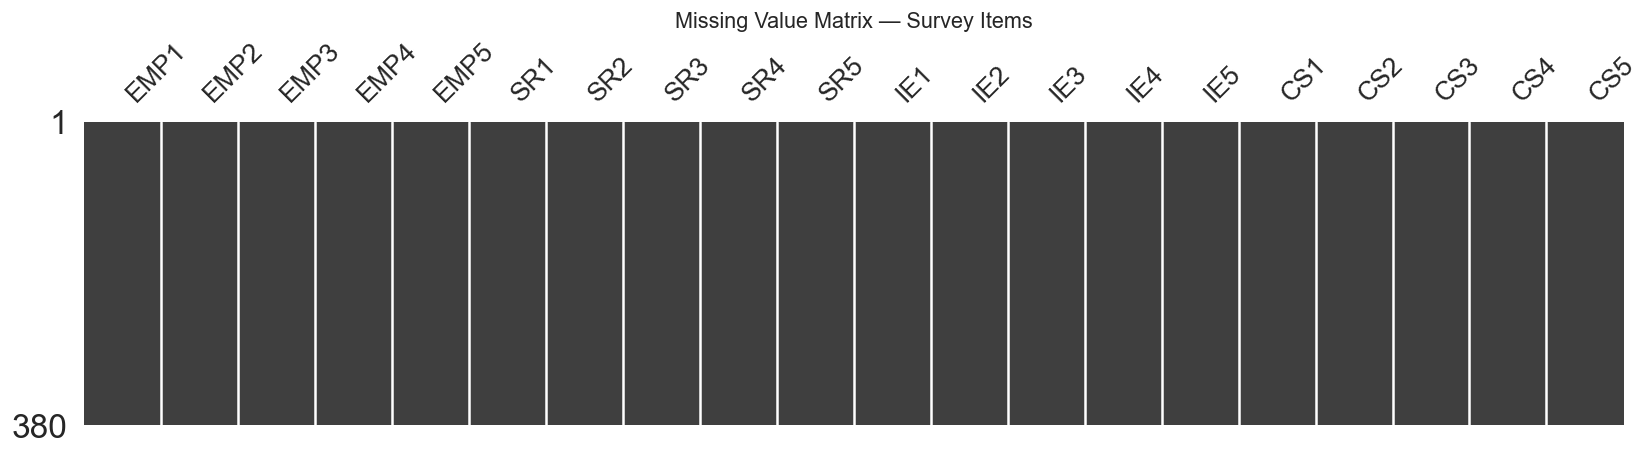

Missing values across the 20 items: 0


In [5]:
fig, ax = plt.subplots(figsize=(14, 4))
msno.matrix(df[all_items], ax=ax, sparkline=False)
ax.set_title('Missing Value Matrix — Survey Items', fontsize=13)
plt.tight_layout()
plt.show()

print('Missing values across the 20 items:', int(df[all_items].isnull().sum().sum()))

In [6]:
z_scores = np.abs(stats.zscore(df[CONSTRUCTS]))
print('Potential outliers (|z| > 3) per construct:')
for c, n in zip(CONSTRUCTS, (z_scores > 3).sum(axis=0)):
    print(f'  {c}: {n}')

Potential outliers (|z| > 3) per construct:
  employability: 0
  skill_relevance: 0
  income_expect: 0
  career_sat: 3


## 3. Descriptive statistics

In [7]:
DEMOGRAPHICS = {
    'Gender': ['Female', 'Male', 'Prefer not to say'],
    'AgeGroup': ['18-21', '22-25', '26-30', 'Above 30'],
    'YearStudy': ['Year 1', 'Year 2', 'Year 3', 'Year 4/Postgraduate'],
    'FieldStudy': ['Business/Management', 'Engineering/Technology', 'Science', 'Social Sciences',
                   'Arts & Humanities', 'Others'],
    'EducationLevel': ["Bachelor's", "Master's", 'Doctorate'],
}
rows = []
for var, cats in DEMOGRAPHICS.items():
    counts = df[var].value_counts()
    for cat in cats:
        rows.append({'Item': var, 'Category': cat, 'n': counts.get(cat, 0),
                     '%': round(counts.get(cat, 0) / len(df) * 100, 1)})
print(pd.DataFrame(rows).to_string(index=False))

          Item               Category   n    %
        Gender                 Female 191 50.3
        Gender                   Male 172 45.3
        Gender      Prefer not to say  17  4.5
      AgeGroup                  18-21 179 47.1
      AgeGroup                  22-25 129 33.9
      AgeGroup                  26-30  44 11.6
      AgeGroup               Above 30  28  7.4
     YearStudy                 Year 1 102 26.8
     YearStudy                 Year 2  88 23.2
     YearStudy                 Year 3  94 24.7
     YearStudy    Year 4/Postgraduate  96 25.3
    FieldStudy    Business/Management 101 26.6
    FieldStudy Engineering/Technology  88 23.2
    FieldStudy                Science  59 15.5
    FieldStudy        Social Sciences  58 15.3
    FieldStudy      Arts & Humanities  52 13.7
    FieldStudy                 Others  22  5.8
EducationLevel             Bachelor's 318 83.7
EducationLevel               Master's  49 12.9
EducationLevel              Doctorate  13  3.4


In [8]:
desc = df[CONSTRUCTS].agg(['count', 'mean', 'std', 'min', 'max']).T
desc.columns = ['N', 'Mean', 'SD', 'Min', 'Max']
desc.round(3)

,N,Mean,SD,Min,Max
employability,380.0,3.972,0.483,3.0,5.0
skill_relevance,380.0,3.967,0.385,3.0,5.0
income_expect,380.0,4.276,0.451,3.0,5.0
career_sat,380.0,4.484,0.469,3.0,5.0


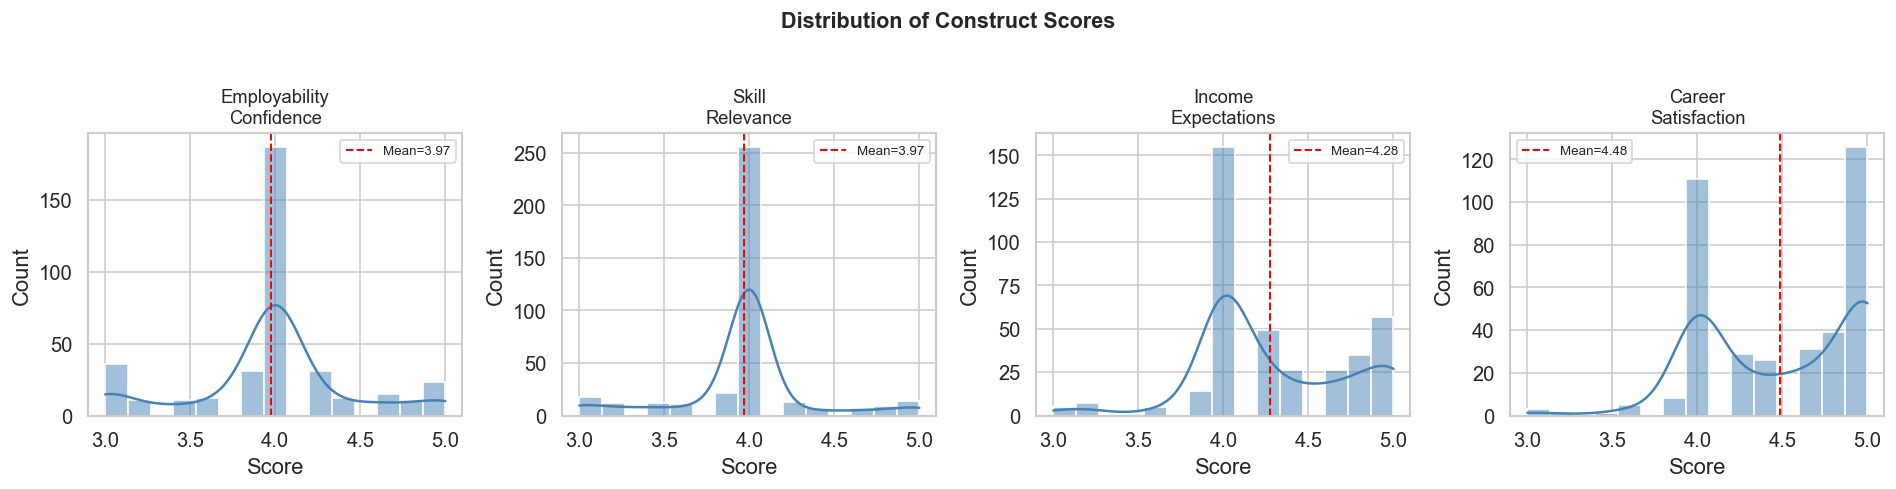

In [9]:
labels = {'employability': 'Employability\nConfidence',
          'skill_relevance': 'Skill\nRelevance',
          'income_expect': 'Income\nExpectations',
          'career_sat': 'Career\nSatisfaction'}

fig, axes = plt.subplots(1, len(CONSTRUCTS), figsize=(4 * len(CONSTRUCTS), 4))
for ax, col in zip(axes, CONSTRUCTS):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue', bins=15)
    ax.set_title(labels[col], fontsize=11)
    ax.set_xlabel('Score')
    ax.set_ylabel('Count')
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.2, label=f'Mean={df[col].mean():.2f}')
    ax.legend(fontsize=8)
plt.suptitle('Distribution of Construct Scores', y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

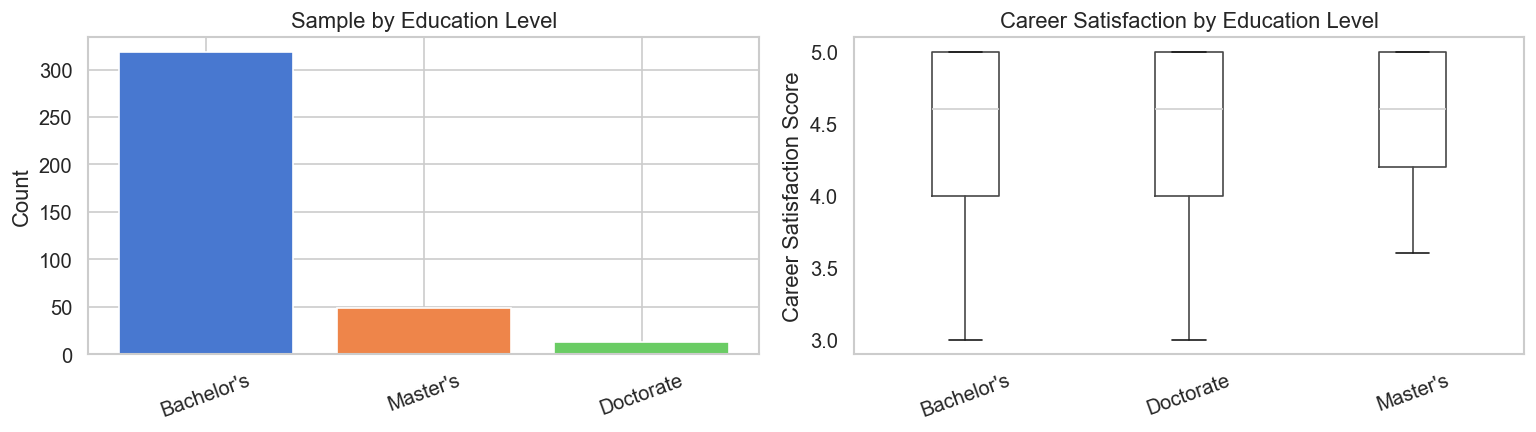

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
edu_counts = df['EducationLevel'].value_counts()
axes[0].bar(edu_counts.index, edu_counts.values, color=sns.color_palette('muted', len(edu_counts)))
axes[0].set_title('Sample by Education Level')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=20)

df.boxplot(column=DV, by='EducationLevel', ax=axes[1], grid=False)
axes[1].set_title('Career Satisfaction by Education Level')
axes[1].set_xlabel('')
axes[1].set_ylabel('Career Satisfaction Score')
axes[1].tick_params(axis='x', rotation=20)
plt.suptitle('')
plt.tight_layout()
plt.show()

## 4. Reliability (Cronbach's alpha)

In [11]:
def cronbach_alpha(items):
    k = items.shape[1]
    return (k / (k - 1)) * (1 - items.var(axis=0, ddof=1).sum() / items.sum(axis=1).var(ddof=1))

pd.DataFrame({'Items': [len(v) for v in CONSTRUCT_MAP.values()],
              'Alpha': [cronbach_alpha(df[v]) for v in CONSTRUCT_MAP.values()]},
             index=CONSTRUCTS).round(3)

,Items,Alpha
employability,5,0.928
skill_relevance,5,0.921
income_expect,5,0.901
career_sat,5,0.918


## 5. Exploratory factor analysis

In [12]:
item_data = df[all_items]
chi2, p = calculate_bartlett_sphericity(item_data)
kmo_all, kmo_model = calculate_kmo(item_data)
print(f"Bartlett's test of sphericity: χ² = {chi2:.2f}, p = {p:.4f}")
print(f'Kaiser-Meyer-Olkin (KMO): {kmo_model:.3f}')

Bartlett's test of sphericity: χ² = 5965.42, p = 0.0000
Kaiser-Meyer-Olkin (KMO): 0.960


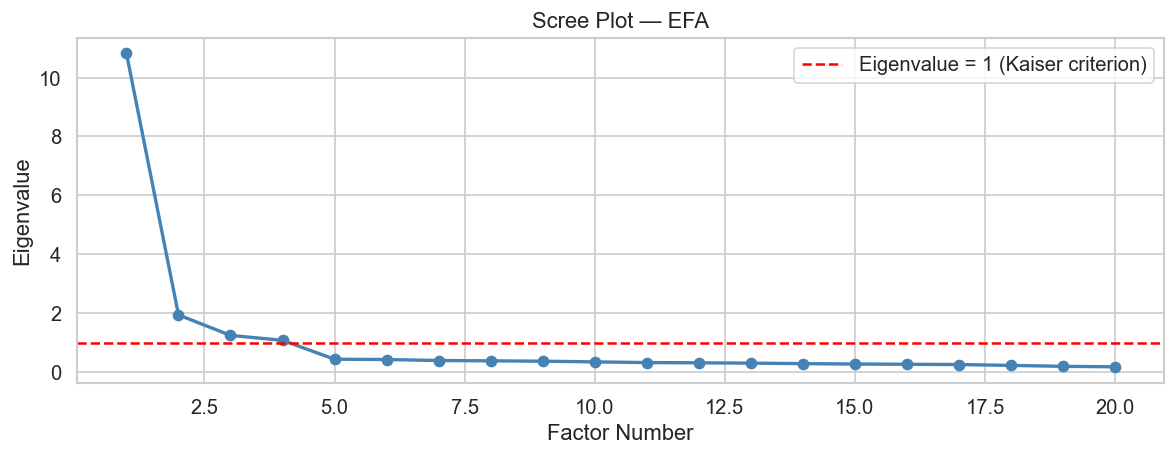

Number of factors with eigenvalue > 1: 4


In [13]:
fa_eigen = FactorAnalyzer(n_factors=len(all_items), rotation=None)
fa_eigen.fit(item_data)
ev, _ = fa_eigen.get_eigenvalues()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, len(ev) + 1), ev, 'o-', color='steelblue', linewidth=2)
ax.axhline(1, color='red', linestyle='--', label='Eigenvalue = 1 (Kaiser criterion)')
ax.set_xlabel('Factor Number')
ax.set_ylabel('Eigenvalue')
ax.set_title('Scree Plot — EFA')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Number of factors with eigenvalue > 1: {(ev > 1).sum()}')

In [14]:
fa = FactorAnalyzer(n_factors=4, rotation='oblimin')
fa.fit(item_data)
loadings = pd.DataFrame(fa.loadings_, index=all_items, columns=['F1', 'F2', 'F3', 'F4'])
print(loadings.round(3).to_string())

variance = pd.DataFrame(fa.get_factor_variance(), index=['SS Loadings', 'Proportion Var', 'Cumulative Var'],
                        columns=['F1', 'F2', 'F3', 'F4'])
print()
print(variance.round(3))
print(f"\nPrimary loading range: {loadings.abs().max(axis=1).min():.3f} to {loadings.abs().max(axis=1).max():.3f}")

         F1     F2     F3     F4
EMP1  0.816  0.040 -0.030  0.062
EMP2  0.848  0.024 -0.005  0.026
EMP3  0.841 -0.022  0.066 -0.066
EMP4  0.825  0.006  0.035  0.014
EMP5  0.790  0.006 -0.002  0.033
SR1  -0.021  0.853 -0.030  0.025
SR2  -0.001  0.871 -0.001  0.000
SR3  -0.020  0.833 -0.022  0.049
SR4   0.101  0.719  0.056 -0.047
SR5   0.006  0.845  0.042 -0.024
IE1  -0.049  0.062  0.051  0.772
IE2  -0.047 -0.015  0.145  0.749
IE3   0.035  0.034 -0.056  0.819
IE4   0.018  0.013  0.047  0.735
IE5   0.136 -0.042 -0.059  0.756
CS1   0.085  0.022  0.732 -0.015
CS2  -0.036 -0.006  0.866  0.030
CS3   0.107  0.007  0.710 -0.004
CS4  -0.000  0.058  0.841 -0.030
CS5  -0.014 -0.023  0.821  0.084

                   F1     F2     F3     F4
SS Loadings     3.451  3.423  3.218  2.965
Proportion Var  0.173  0.171  0.161  0.148
Cumulative Var  0.173  0.344  0.505  0.653

Primary loading range: 0.710 to 0.871


## 6. Correlations

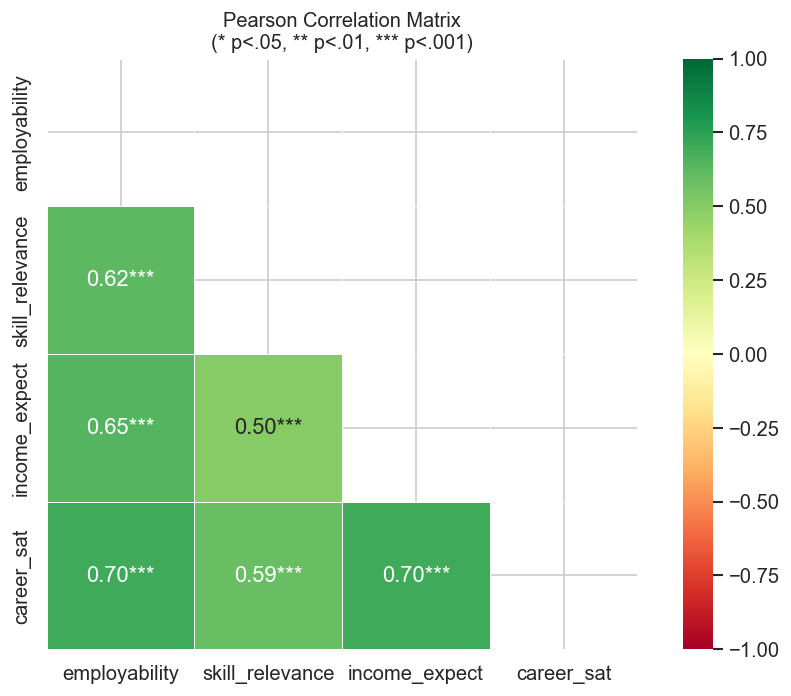

,employability,skill_relevance,income_expect,career_sat
employability,1.000,0.618,0.646,0.697
skill_relevance,0.618,1.000,0.499,0.591
income_expect,0.646,0.499,1.000,0.696
career_sat,0.697,0.591,0.696,1.000


In [15]:
corr_matrix = df[CONSTRUCTS].corr()
p_matrix = pd.DataFrame(np.ones((4, 4)), index=CONSTRUCTS, columns=CONSTRUCTS)
for i in CONSTRUCTS:
    for j in CONSTRUCTS:
        if i != j:
            p_matrix.loc[i, j] = pearsonr(df[i], df[j])[1]

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
annot = corr_matrix.round(2).astype(str)
for a, i in enumerate(CONSTRUCTS):
    for b, j in enumerate(CONSTRUCTS):
        if i != j and not mask[a, b]:
            p = p_matrix.loc[i, j]
            stars = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
            annot.loc[i, j] = f'{corr_matrix.loc[i, j]:.2f}{stars}'

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, mask=mask, annot=annot, fmt='', cmap='RdYlGn',
            vmin=-1, vmax=1, center=0, ax=ax, square=True, linewidths=0.5)
ax.set_title('Pearson Correlation Matrix\n(* p<.05, ** p<.01, *** p<.001)', fontsize=12)
plt.tight_layout()
plt.show()

corr_matrix.round(3)

## 7. Multiple regression

In [16]:
X = df[IVs]
y = df[DV]
model = sm.OLS(y, sm.add_constant(X)).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             career_sat   R-squared:                       0.613
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     198.3
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           4.21e-77
Time:                        16:21:40   Log-Likelihood:                -70.949
No. Observations:                 380   AIC:                             149.9
Df Residuals:                     376   BIC:                             165.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.5520      0.173     

In [17]:
X_vif = sm.add_constant(X)
vif = pd.DataFrame({'Variable': X_vif.columns,
                    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
print(vif[vif['Variable'] != 'const'].round(3).to_string(index=False))

       Variable   VIF
  employability 2.145
skill_relevance 1.663
  income_expect 1.766


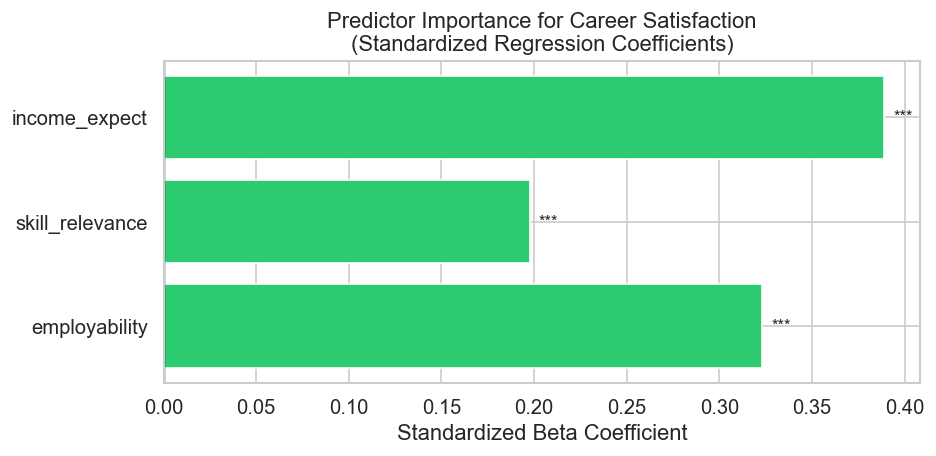

R² = 0.613, adjusted R² = 0.610
Standardized betas: {'employability': 0.323, 'skill_relevance': 0.198, 'income_expect': 0.389}


In [18]:
scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X), columns=IVs)
y_std = pd.Series(scaler.fit_transform(y.values.reshape(-1, 1)).flatten())
model_std = sm.OLS(y_std, sm.add_constant(X_std)).fit()
betas = model_std.params[1:]
p_vals = model_std.pvalues[1:]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(IVs, betas, color=['#2ecc71' if b > 0 else '#e74c3c' for b in betas], edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Standardized Beta Coefficient')
ax.set_title('Predictor Importance for Career Satisfaction\n(Standardized Regression Coefficients)')
for bar, p in zip(bars, p_vals):
    stars = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2, stars, va='center', fontsize=10)
plt.tight_layout()
plt.show()

print(f'R² = {model_std.rsquared:.3f}, adjusted R² = {model_std.rsquared_adj:.3f}')
print('Standardized betas:', betas.round(3).to_dict())

In [19]:
def std_coefs(data):
    z = (data - data.mean()) / data.std()
    return sm.OLS(z[DV], sm.add_constant(z[IVs])).fit().params[IVs].values

reg_data = df[IVs + [DV]]
base = std_coefs(reg_data)
rng = np.random.default_rng(42)
n = len(reg_data)
boot = np.array([std_coefs(reg_data.iloc[rng.integers(0, n, n)]) for _ in range(5000)])

print('Differences between standardized coefficients (percentile bootstrap, 5,000 resamples, seed 42)')
for a, b in [('income_expect', 'skill_relevance'), ('income_expect', 'employability'),
             ('employability', 'skill_relevance')]:
    i, j = IVs.index(a), IVs.index(b)
    diff = boot[:, i] - boot[:, j]
    lo, hi = np.percentile(diff, [2.5, 97.5])
    p = 2 * min((diff <= 0).mean(), (diff >= 0).mean())
    print(f'  {a} - {b}: Δβ = {base[i] - base[j]:.3f}, 95% CI [{lo:.3f}, {hi:.3f}], p = {p:.3f}')

Differences between standardized coefficients (percentile bootstrap, 5,000 resamples, seed 42)
  income_expect - skill_relevance: Δβ = 0.192, 95% CI [0.090, 0.298], p = 0.000
  income_expect - employability: Δβ = 0.066, 95% CI [-0.085, 0.215], p = 0.375
  employability - skill_relevance: Δβ = 0.125, 95% CI [0.002, 0.257], p = 0.047


## 8. Structural equation model

In [20]:
model_spec = '\n'.join([f"{c} =~ {' + '.join(items)}" for c, items in CONSTRUCT_MAP.items()]
                       + ['', f"career_sat ~ {' + '.join(IVs)}"])
print(model_spec)

employability =~ EMP1 + EMP2 + EMP3 + EMP4 + EMP5
skill_relevance =~ SR1 + SR2 + SR3 + SR4 + SR5
income_expect =~ IE1 + IE2 + IE3 + IE4 + IE5
career_sat =~ CS1 + CS2 + CS3 + CS4 + CS5

career_sat ~ employability + skill_relevance + income_expect


In [21]:
sem_data = df[all_items]
sem_model = semopy.Model(model_spec)
sem_model.fit(sem_data)
stats_sem = semopy.calc_stats(sem_model)

obs = sem_model.vars['observed']
S = sem_data[obs].cov(ddof=0).values
Sigma = sem_model.calc_sigma()[0]
d = np.sqrt(np.diag(S))
resid = (S - Sigma) / np.outer(d, d)
srmr = np.sqrt(np.mean(resid[np.tril_indices(len(obs))] ** 2))

fit_indices = pd.DataFrame({
    'Value': [stats_sem['chi2'].iloc[0], stats_sem['DoF'].iloc[0], stats_sem['chi2 p-value'].iloc[0],
              stats_sem['chi2'].iloc[0] / stats_sem['DoF'].iloc[0],
              stats_sem['CFI'].iloc[0], stats_sem['TLI'].iloc[0], stats_sem['RMSEA'].iloc[0], srmr],
    'Threshold': ['—', '—', '> .05', '< 3', '≥ .95', '≥ .95', '≤ .06', '≤ .08'],
}, index=['χ²', 'df', 'p-value', 'χ²/df', 'CFI', 'TLI', 'RMSEA', 'SRMR'])
print(f'SEM fit statistics (N = {len(sem_data)})')
print(fit_indices.round(3).to_string())

SEM fit statistics (N = 380)
           Value Threshold
χ²       169.808         —
df       164.000         —
p-value    0.362     > .05
χ²/df      1.035       < 3
CFI        0.999     ≥ .95
TLI        0.999     ≥ .95
RMSEA      0.010     ≤ .06
SRMR       0.021     ≤ .08


In [22]:
print(stats_sem.T.round(3).to_string())

                  Value
DoF             164.000
DoF Baseline    190.000
chi2            169.808
chi2 p-value      0.362
chi2 Baseline  6101.913
CFI               0.999
GFI               0.972
AGFI              0.968
NFI               0.972
TLI               0.999
RMSEA             0.010
AIC              91.106
BIC             272.354
LogLik            0.447


In [23]:
params = sem_model.inspect(std_est=True)
params['p-value'] = pd.to_numeric(params['p-value'], errors='coerce')
print(params.round(3).to_string())

structural = params[(params['op'] == '~') & (params['lval'] == 'career_sat')]
print()
print(structural[['rval', 'Estimate', 'Est. Std', 'Std. Err', 'z-value', 'p-value']].round(3).to_string(index=False))

resid_std = params[(params['op'] == '~~') & (params['lval'] == DV) & (params['rval'] == DV)]['Est. Std'].iloc[0]
print(f'\nR² of latent career satisfaction: {1 - resid_std:.3f}')

               lval  op             rval  Estimate  Est. Std  Std. Err    z-value  p-value
0        career_sat   ~    employability     0.282     0.309  0.056938   4.944501      0.0
1        career_sat   ~  skill_relevance     0.235     0.188  0.062894   3.739786      0.0
2        career_sat   ~    income_expect     0.457     0.447  0.060295   7.584175      0.0
3              EMP1   ~    employability     1.000     0.862         -          -      NaN
4              EMP2   ~    employability     1.052     0.881  0.045457  23.151716      0.0
5              EMP3   ~    employability     0.932     0.824  0.045357  20.547926      0.0
6              EMP4   ~    employability     0.992     0.863  0.044502  22.302428      0.0
7              EMP5   ~    employability     0.913     0.815  0.045244  20.168907      0.0
8               SR1   ~  skill_relevance     1.000     0.828         -          -      NaN
9               SR2   ~  skill_relevance     1.116     0.871  0.053502  20.867195      0.0

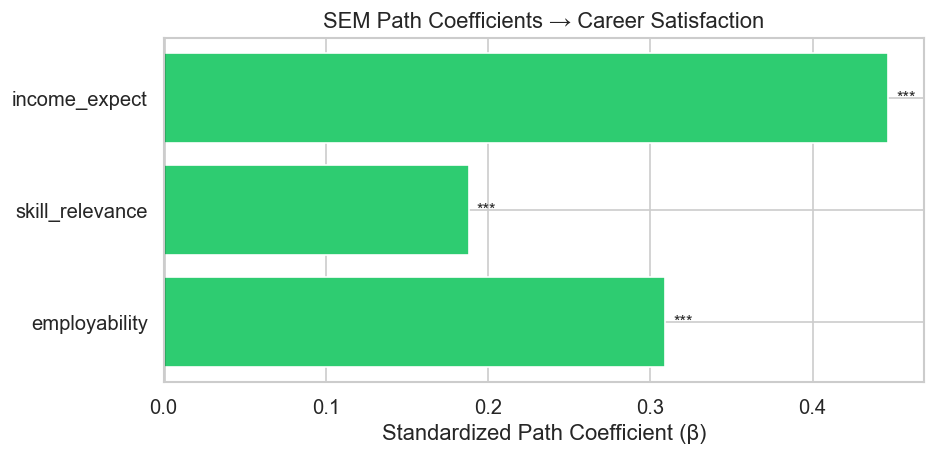

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(structural['rval'], structural['Est. Std'],
               color=['#2ecc71' if e > 0 else '#e74c3c' for e in structural['Est. Std']])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Standardized Path Coefficient (β)')
ax.set_title('SEM Path Coefficients → Career Satisfaction')
for bar, p in zip(bars, structural['p-value']):
    stars = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2, stars, va='center', fontsize=10)
plt.tight_layout()
plt.show()

## 9. Career satisfaction by education level

In [25]:
print(pg.anova(data=df, dv=DV, between='EducationLevel', detailed=True).round(4).to_string())

           Source       SS   DF      MS       F   p_unc     np2
0  EducationLevel   0.1943    2  0.0972  0.4398  0.6445  0.0023
1          Within  83.2710  377  0.2209     NaN     NaN     NaN


## 10. Income expectation–career satisfaction gap

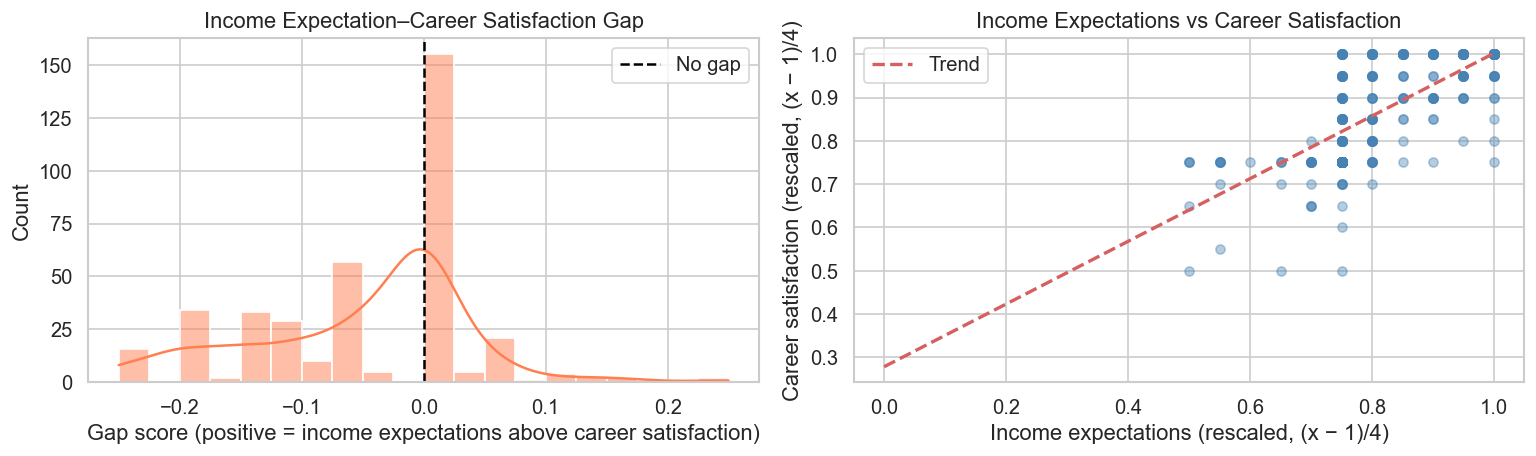

Gap = (income expectations - 1)/4 - (career satisfaction - 1)/4
Mean gap score: -0.052 (SD 0.090)
Respondents with income expectations above career satisfaction (gap > 0): 39 (10.3%)


In [26]:
gap_norm = (df[['income_expect', 'career_sat']] - 1) / 4
gap_norm['expectation_gap'] = gap_norm['income_expect'] - gap_norm['career_sat']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(gap_norm['expectation_gap'], kde=True, ax=axes[0], color='coral', bins=20)
axes[0].axvline(0, color='black', linestyle='--', linewidth=1.5, label='No gap')
axes[0].set_title('Income Expectation–Career Satisfaction Gap')
axes[0].set_xlabel('Gap score (positive = income expectations above career satisfaction)')
axes[0].legend()

axes[1].scatter(gap_norm['income_expect'], gap_norm['career_sat'], alpha=0.4, color='steelblue', s=30)
trend = np.poly1d(np.polyfit(gap_norm['income_expect'], gap_norm['career_sat'], 1))
x_line = np.linspace(0, 1, 100)
axes[1].plot(x_line, trend(x_line), 'r--', linewidth=2, label='Trend')
axes[1].set_xlabel('Income expectations (rescaled, (x − 1)/4)')
axes[1].set_ylabel('Career satisfaction (rescaled, (x − 1)/4)')
axes[1].set_title('Income Expectations vs Career Satisfaction')
axes[1].legend()
plt.tight_layout()
plt.show()

gap = gap_norm['expectation_gap']
print('Gap = (income expectations - 1)/4 - (career satisfaction - 1)/4')
print(f'Mean gap score: {gap.mean():.3f} (SD {gap.std():.3f})')
print(f'Respondents with income expectations above career satisfaction (gap > 0): {(gap > 0).sum()} ({(gap > 0).mean() * 100:.1f}%)')

## 11. Robustness checks

In [27]:
values = pd.Series(df[all_items].values.ravel())
print('Response distribution across all items:', values.value_counts().sort_index().to_dict())
print(f'Responses of 1 or 2 (Disagree / Strongly Disagree): {(values < 3).sum()}')

Response distribution across all items: {3: 649, 4: 4974, 5: 1977}
Responses of 1 or 2 (Disagree / Strongly Disagree): 0


In [28]:
def std_betas(data):
    z = (data - data.mean()) / data.std()
    return sm.OLS(z[DV], sm.add_constant(z[IVs])).fit()

keep = (np.abs(stats.zscore(df[CONSTRUCTS])) <= 3).all(axis=1)
for label, data in [('All cases', df[CONSTRUCTS]), ('Outliers removed', df.loc[keep, CONSTRUCTS])]:
    fit = std_betas(data)
    print(f"{label:<17} n={len(data)}  R²={fit.rsquared:.3f}  β:", fit.params[IVs].round(3).to_dict())

All cases         n=380  R²=0.613  β: {'employability': 0.323, 'skill_relevance': 0.198, 'income_expect': 0.389}
Outliers removed  n=377  R²=0.602  β: {'employability': 0.309, 'skill_relevance': 0.197, 'income_expect': 0.4}


In [29]:
rng = np.random.default_rng(42)
boot = np.array([std_betas(df[CONSTRUCTS].iloc[rng.integers(0, len(df), len(df))]).params[IVs].values
                 for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
base = std_betas(df[CONSTRUCTS]).params[IVs]
print('Bootstrap 95% CIs for standardized betas (2,000 resamples):')
for name, b, l, h in zip(IVs, base, lo, hi):
    print(f'  {name:<16} β = {b:.3f}  [{l:.3f}, {h:.3f}]')

Bootstrap 95% CIs for standardized betas (2,000 resamples):
  employability    β = 0.323  [0.240, 0.405]
  skill_relevance  β = 0.198  [0.133, 0.256]
  income_expect    β = 0.389  [0.309, 0.467]


In [30]:
print('Spearman ρ with career satisfaction:', df[CONSTRUCTS].corr('spearman')[DV].drop(DV).round(3).to_dict())
hc3 = sm.OLS(df[DV], sm.add_constant(df[IVs])).fit(cov_type='HC3')
print(pd.DataFrame({'B': hc3.params, 'HC3 SE': hc3.bse, 't': hc3.tvalues, 'p': hc3.pvalues}).round(4).to_string())

Spearman ρ with career satisfaction: {'employability': 0.735, 'skill_relevance': 0.636, 'income_expect': 0.733}
                      B  HC3 SE       t       p
const            0.5520  0.1583  3.4865  0.0005
employability    0.3138  0.0400  7.8485  0.0000
skill_relevance  0.2410  0.0404  5.9636  0.0000
income_expect    0.4046  0.0421  9.6173  0.0000


## 12. Summary figure

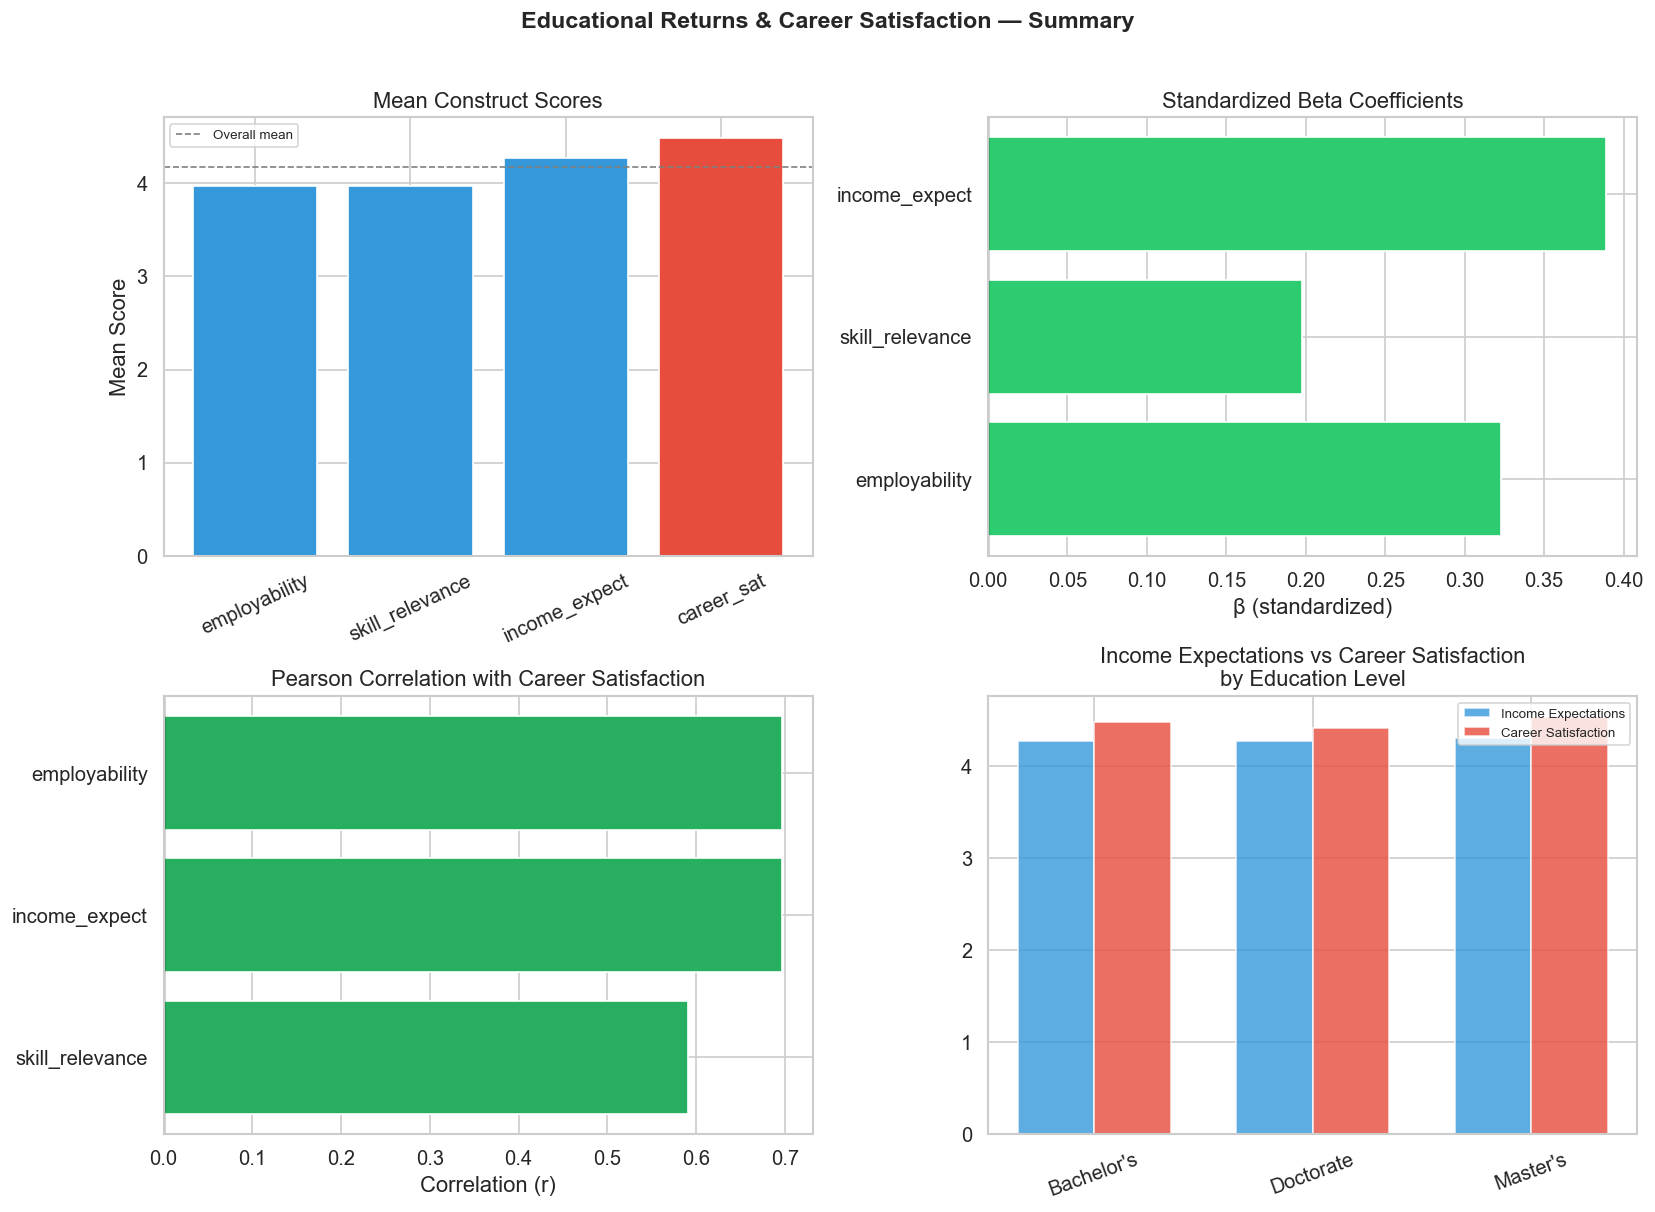

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Educational Returns & Career Satisfaction — Summary', fontsize=14, fontweight='bold', y=1.01)

means = df[CONSTRUCTS].mean()
axes[0, 0].bar(means.index, means.values, color=['#3498db'] * 3 + ['#e74c3c'], edgecolor='white')
axes[0, 0].axhline(means.mean(), color='gray', linestyle='--', linewidth=1, label='Overall mean')
axes[0, 0].set_title('Mean Construct Scores')
axes[0, 0].set_ylabel('Mean Score')
axes[0, 0].tick_params(axis='x', rotation=25)
axes[0, 0].legend(fontsize=8)

axes[0, 1].barh(IVs, betas.values, color=['#2ecc71' if b > 0 else '#e74c3c' for b in betas.values])
axes[0, 1].axvline(0, color='black', linewidth=0.8)
axes[0, 1].set_title('Standardized Beta Coefficients')
axes[0, 1].set_xlabel('β (standardized)')

corr_with_dv = corr_matrix[DV].drop(DV).sort_values()
axes[1, 0].barh(corr_with_dv.index, corr_with_dv.values,
                color=['#27ae60' if v > 0 else '#c0392b' for v in corr_with_dv.values])
axes[1, 0].axvline(0, color='black', linewidth=0.8)
axes[1, 0].set_title('Pearson Correlation with Career Satisfaction')
axes[1, 0].set_xlabel('Correlation (r)')

by_edu = df.groupby('EducationLevel')[['income_expect', 'career_sat']].mean()
x = np.arange(len(by_edu))
axes[1, 1].bar(x - 0.175, by_edu['income_expect'], 0.35, label='Income Expectations', color='#3498db', alpha=0.8)
axes[1, 1].bar(x + 0.175, by_edu['career_sat'], 0.35, label='Career Satisfaction', color='#e74c3c', alpha=0.8)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(by_edu.index, rotation=20)
axes[1, 1].set_title('Income Expectations vs Career Satisfaction\nby Education Level')
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 13. Export results

In [32]:
with pd.ExcelWriter('analysis_results.xlsx', engine='openpyxl') as writer:
    df[CONSTRUCTS].describe().round(3).to_excel(writer, sheet_name='Descriptives')
    corr_matrix.round(3).to_excel(writer, sheet_name='Correlations')
    model.summary2().tables[1].to_excel(writer, sheet_name='Regression')
    fit_indices.round(3).to_excel(writer, sheet_name='SEM_Fit')
    params.round(3).to_excel(writer, sheet_name='SEM_Paths', index=False)
print('Saved: analysis_results.xlsx')

Saved: analysis_results.xlsx


## 14. Figure: distribution of the gap

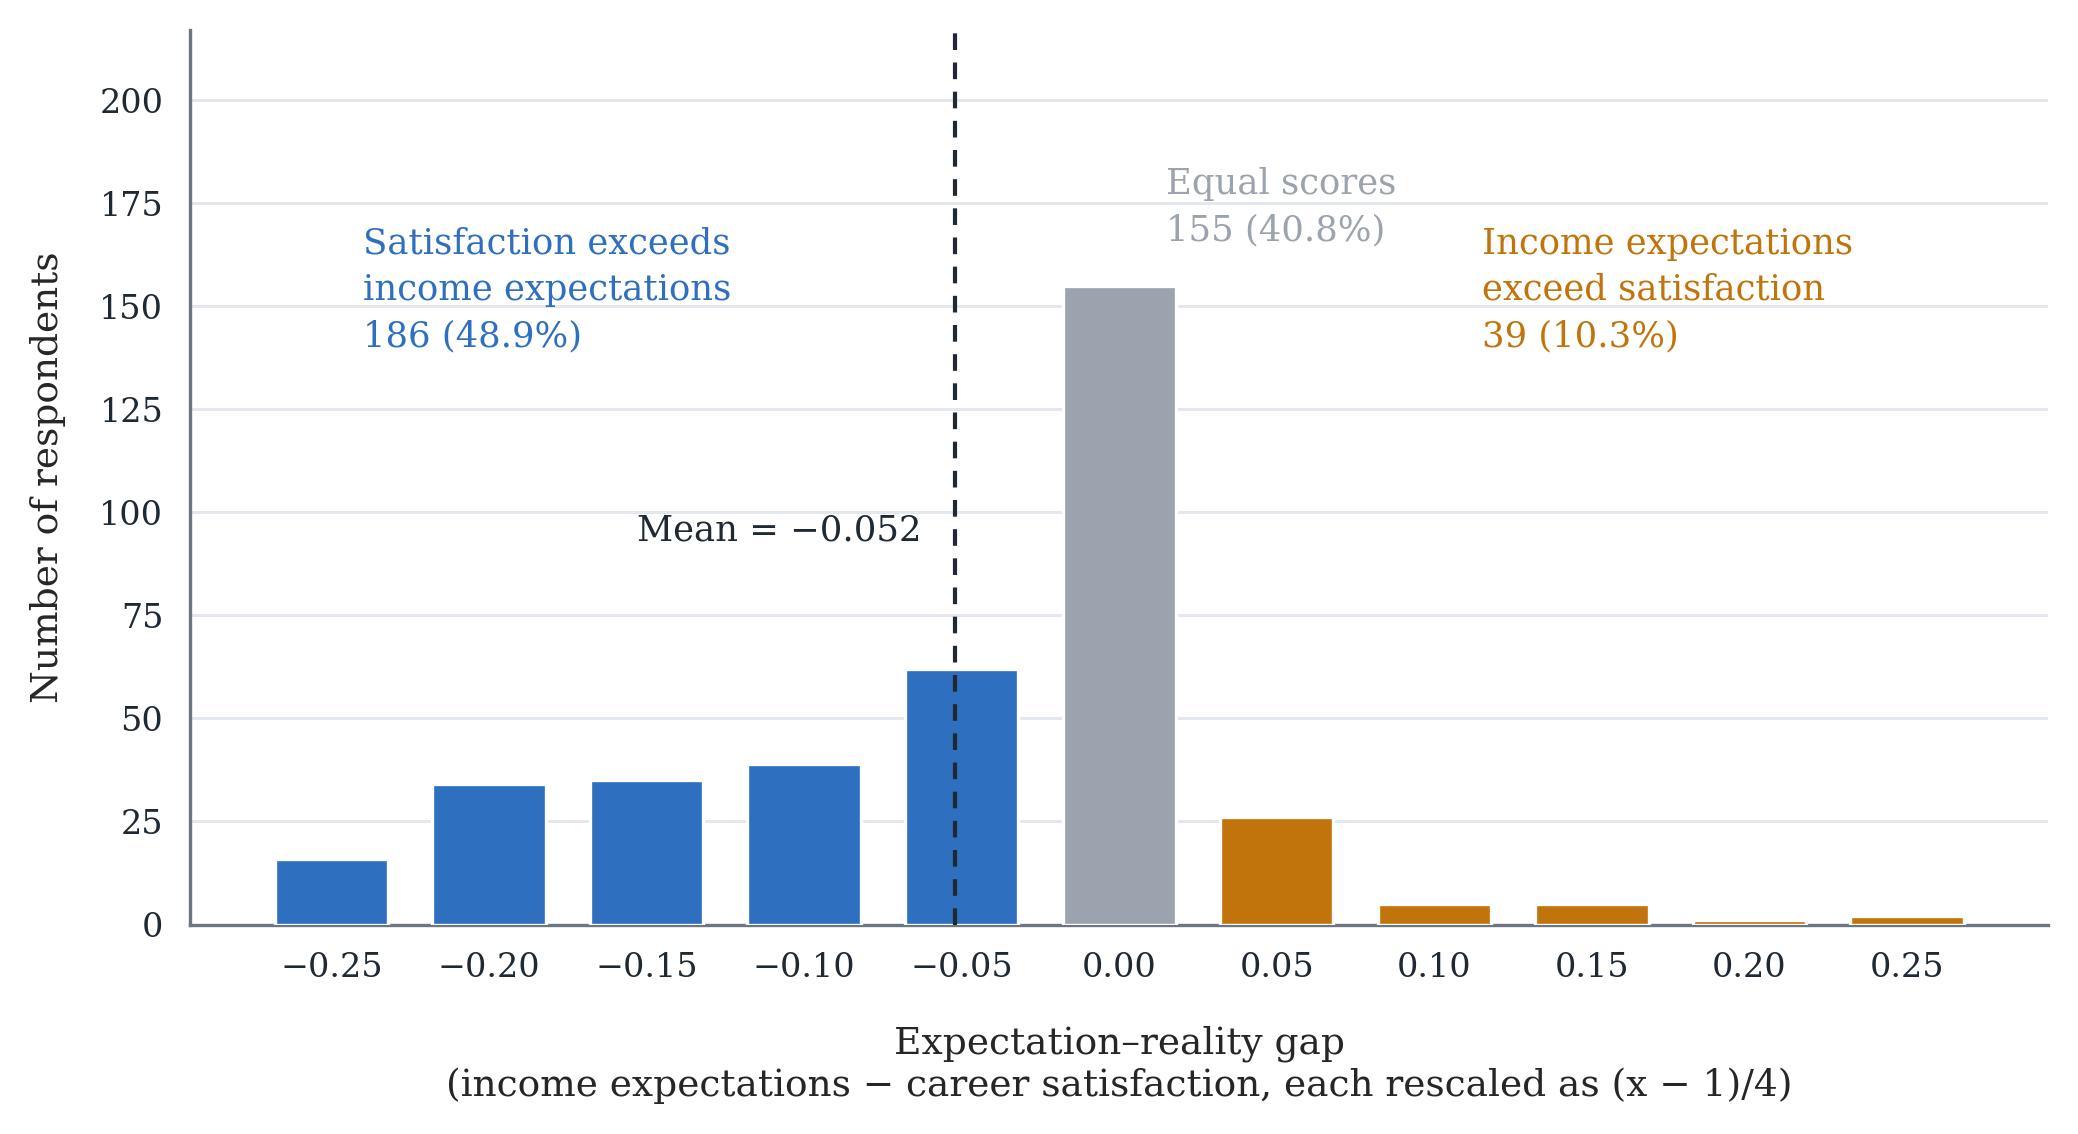

Saved figure2_expectation_gap.png | N=380 | mean=-0.052 | below=186 zero=155 above=39 (10.3%)


In [33]:
counts = gap.round(6).value_counts().sort_index()
mean_gap = gap.mean()
n_below, n_zero, n_above = (gap.round(6) < 0).sum(), (gap.round(6) == 0).sum(), (gap.round(6) > 0).sum()
N = len(gap)

BLUE, GREY, AMBER = '#2F6FBF', '#9AA3AE', '#C2740C'
INK, MUTED, GRID = '#1F2933', '#6B7682', '#E3E7EE'
plt.rcParams.update({'font.family': 'serif', 'font.size': 9, 'axes.edgecolor': MUTED, 'axes.linewidth': 0.8,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})

fig, ax = plt.subplots(figsize=(7.2, 4.2), dpi=300)
ax.bar(counts.index, counts.values, width=0.036,
       color=[BLUE if v < 0 else (GREY if v == 0 else AMBER) for v in counts.index],
       edgecolor='white', linewidth=0.8, zorder=3)
ax.axvline(mean_gap, color=INK, lw=1.0, ls=(0, (4, 3)), zorder=4)
ax.set_ylim(0, counts.max() * 1.40)
ymax = ax.get_ylim()[1]

ax.text(-0.24, ymax * 0.78, f'Satisfaction exceeds\nincome expectations\n{n_below} ({n_below / N * 100:.1f}%)',
        color=BLUE, fontsize=8.5, va='top', ha='left', linespacing=1.45)
ax.text(0.015, counts.max() * 1.06, f'Equal scores\n{n_zero} ({n_zero / N * 100:.1f}%)',
        color=GREY, fontsize=8.5, va='bottom', ha='left', linespacing=1.45)
ax.text(0.115, ymax * 0.78, f'Income expectations\nexceed satisfaction\n{n_above} ({n_above / N * 100:.1f}%)',
        color=AMBER, fontsize=8.5, va='top', ha='left', linespacing=1.45)
ax.annotate('Mean = ' + f'{mean_gap:.3f}'.replace('-', '\u2212'), xy=(mean_gap, ymax * 0.44), xytext=(-8, 0),
            textcoords='offset points', ha='right', va='center', fontsize=8.5, color=INK)

ax.set_xlabel('Expectation–reality gap\n(income expectations − career satisfaction, each rescaled as (x − 1)/4)',
              labelpad=10, fontsize=9)
ax.set_ylabel('Number of respondents', labelpad=8, fontsize=9)
ticks = np.round(np.arange(-0.25, 0.251, 0.05), 2)
ax.set_xticks(ticks)
ax.set_xticklabels([('0.00' if abs(t) < 1e-9 else f'{t:.2f}').replace('-', '\u2212') for t in ticks])
ax.yaxis.grid(True, color=GRID, lw=0.7, zorder=0)
ax.xaxis.grid(False)
ax.tick_params(axis='both', labelsize=8, colors=MUTED, length=3)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
for lbl in ax.get_xticklabels() + ax.get_yticklabels():
    lbl.set_color(INK)
fig.subplots_adjust(left=0.11, right=0.97, top=0.94, bottom=0.23)
fig.savefig('figure2_expectation_gap.png', dpi=300, bbox_inches='tight', pad_inches=0.15, facecolor='white')
plt.show()

print(f'Saved figure2_expectation_gap.png | N={N} | mean={mean_gap:.3f} | '
      f'below={n_below} zero={n_zero} above={n_above} ({n_above / N * 100:.1f}%)')

## 15. Mediation through employability confidence

In [34]:
N_BOOT, SEED = 5000, 42
M = 'employability'


def ols(y, xs, d):
    return sm.OLS(d[y], sm.add_constant(d[xs])).fit()


def indirect(d, X, cov):
    return ols(M, [X, cov], d).params[X] * ols(DV, [X, M, cov], d).params[M]


def bc_ci(boot, est, alpha=0.05):
    z0 = norm.ppf((boot < est).mean())
    lo = norm.cdf(2 * z0 + norm.ppf(alpha / 2))
    hi = norm.cdf(2 * z0 + norm.ppf(1 - alpha / 2))
    return np.percentile(boot, [lo * 100, hi * 100])


med_data = df[CONSTRUCTS]
paths, effects = [], []
for X, cov in [('skill_relevance', 'income_expect'), ('income_expect', 'skill_relevance')]:
    a_fit = ols(M, [X, cov], med_data)
    y_fit = ols(DV, [X, M, cov], med_data)
    c_fit = ols(DV, [X, cov], med_data)
    ind = a_fit.params[X] * y_fit.params[M]

    rng = np.random.default_rng(SEED)
    n = len(med_data)
    boot = np.array([indirect(med_data.iloc[rng.integers(0, n, n)], X, cov) for _ in range(N_BOOT)])
    bc_lo, bc_hi = bc_ci(boot, ind)
    pc_lo, pc_hi = np.percentile(boot, [2.5, 97.5])

    for label, fit, var in [(f'a: {X} -> {M}', a_fit, X), (f'b: {M} -> {DV}', y_fit, M),
                            (f"c': {X} -> {DV} (direct)", y_fit, X), (f'c: {X} -> {DV} (total)', c_fit, X)]:
        ci = fit.conf_int().loc[var]
        paths.append({'Model': f'X = {X}', 'Path': label, 'B': fit.params[var], 'SE': fit.bse[var],
                      't': fit.tvalues[var], 'p': fit.pvalues[var], 'LLCI': ci[0], 'ULCI': ci[1]})
    effects.append({'X': X, 'Covariate': cov, 'a': a_fit.params[X], 'b': y_fit.params[M],
                    'Indirect (a*b)': ind, 'BootSE': boot.std(ddof=1),
                    'BC LLCI': bc_lo, 'BC ULCI': bc_hi, 'Pct LLCI': pc_lo, 'Pct ULCI': pc_hi,
                    'Std. indirect': ind * med_data[X].std() / med_data[DV].std(),
                    "Direct c'": y_fit.params[X], 'Total c': c_fit.params[X],
                    'Proportion mediated': ind / c_fit.params[X],
                    'R2 (M model)': a_fit.rsquared, 'R2 (Y model)': y_fit.rsquared})

paths_df, effects_df = pd.DataFrame(paths), pd.DataFrame(effects)
print('Regression paths (unstandardized B)')
print(paths_df.round(3).to_string(index=False))
print(f'\nIndirect effects via employability confidence ({N_BOOT} bootstrap resamples, seed {SEED})')
print(effects_df.round(3).T.to_string(header=False))

with pd.ExcelWriter('mediation_results.xlsx', engine='openpyxl') as writer:
    paths_df.round(4).to_excel(writer, sheet_name='Paths', index=False)
    effects_df.round(4).to_excel(writer, sheet_name='Indirect_effects', index=False)
print('Saved: mediation_results.xlsx')

Regression paths (unstandardized B)
              Model                                       Path     B    SE      t   p  LLCI  ULCI
X = skill_relevance        a: skill_relevance -> employability 0.494 0.051  9.693 0.0 0.394 0.594
X = skill_relevance             b: employability -> career_sat 0.314 0.046  6.872 0.0 0.224 0.404
X = skill_relevance c': skill_relevance -> career_sat (direct) 0.241 0.050  4.773 0.0 0.142 0.340
X = skill_relevance   c: skill_relevance -> career_sat (total) 0.396 0.048  8.273 0.0 0.302 0.490
  X = income_expect          a: income_expect -> employability 0.482 0.043 11.092 0.0 0.396 0.567
  X = income_expect             b: employability -> career_sat 0.314 0.046  6.872 0.0 0.224 0.404
  X = income_expect   c': income_expect -> career_sat (direct) 0.405 0.044  9.123 0.0 0.317 0.492
  X = income_expect     c: income_expect -> career_sat (total) 0.556 0.041 13.621 0.0 0.476 0.636

Indirect effects via employability confidence (5000 bootstrap resamples, seed 42)

## 16. Common method variance

In [35]:
eigenvalues = np.linalg.eigvalsh(df[all_items].corr().values)[::-1]
print(f"Harman's single-factor test: first unrotated factor explains {eigenvalues[0] / len(all_items) * 100:.1f}% of the variance")

Harman's single-factor test: first unrotated factor explains 54.1% of the variance


In [36]:
four_factor = '\n'.join(f"{c} =~ {' + '.join(items)}" for c, items in CONSTRUCT_MAP.items())
one_factor = 'common =~ ' + ' + '.join(all_items)

cmv_fit = {}
for name, spec in [('Four-factor CFA', four_factor), ('One-factor CFA', one_factor)]:
    m = semopy.Model(spec)
    m.fit(df[all_items])
    cmv_fit[name] = semopy.calc_stats(m)[['chi2', 'DoF', 'CFI', 'TLI', 'RMSEA']].iloc[0]
cmv_fit = pd.DataFrame(cmv_fit).T
print(cmv_fit.round(3).to_string())

d_chi2 = cmv_fit.loc['One-factor CFA', 'chi2'] - cmv_fit.loc['Four-factor CFA', 'chi2']
d_df = cmv_fit.loc['One-factor CFA', 'DoF'] - cmv_fit.loc['Four-factor CFA', 'DoF']
print(f'\nΔχ²({int(d_df)}) = {d_chi2:.2f}, p = {stats.chi2.sf(d_chi2, d_df):.3g}')

                     chi2    DoF    CFI    TLI  RMSEA
Four-factor CFA   169.808  164.0  0.999  0.999  0.010
One-factor CFA   1678.563  170.0  0.745  0.715  0.153

Δχ²(6) = 1508.75, p = 0


In [37]:
ulmc_spec = (four_factor + '\nmethod =~ ' + ' + '.join(all_items) + '\n'
             + '\n'.join(f'method ~~ 0*{c}' for c in CONSTRUCT_MAP))
ulmc = semopy.Model(ulmc_spec)
ulmc.fit(df[all_items])
print(semopy.calc_stats(ulmc)[['chi2', 'DoF', 'CFI', 'TLI', 'RMSEA']].T.round(3).to_string())

est = ulmc.inspect(std_est=True)
method_loadings = est[(est['op'] == '~') & (est['rval'] == 'method')]['Est. Std'].astype(float)
trait_loadings = est[(est['op'] == '~') & (est['rval'].isin(CONSTRUCTS))]['Est. Std'].astype(float)
print(f'\nMean squared method loading (share of item variance): {(method_loadings ** 2).mean() * 100:.1f}%')
print(f'Mean squared trait loading (share of item variance): {(trait_loadings ** 2).mean() * 100:.1f}%')
print(f'Mean standardized trait loading: {trait_loadings.mean():.2f}')

         Value
chi2   137.057
DoF    144.000
CFI      1.001
TLI      1.002
RMSEA    0.000

Mean squared method loading (share of item variance): 2.8%
Mean squared trait loading (share of item variance): 67.1%
Mean standardized trait loading: 0.82


## 17. Measurement model (CFA): loadings, CR, AVE, discriminant validity

In [38]:
cfa = semopy.Model(four_factor)
cfa.fit(df[all_items])
cfa_est = cfa.inspect(std_est=True)
cfa_est['p-value'] = pd.to_numeric(cfa_est['p-value'], errors='coerce')

load = cfa_est[(cfa_est['op'] == '~') & (cfa_est['rval'].isin(CONSTRUCTS))]
print(f"Standardized loadings: {load['Est. Std'].min():.3f} to {load['Est. Std'].max():.3f}; "
      f"largest p-value among the freely estimated loadings: {load['p-value'].max():.3g}")

rows = []
for c in CONSTRUCTS:
    lam = load.loc[load['rval'] == c, 'Est. Std'].astype(float)
    cr = lam.sum() ** 2 / (lam.sum() ** 2 + (1 - lam ** 2).sum())
    ave = (lam ** 2).mean()
    rows.append({'Construct': c, 'CR': cr, 'AVE': ave, 'sqrt(AVE)': np.sqrt(ave)})
cr_ave = pd.DataFrame(rows).set_index('Construct')
print(cr_ave.round(3).to_string())

Standardized loadings: 0.780 to 0.881; largest p-value among the freely estimated loadings: 0
                    CR    AVE  sqrt(AVE)
Construct                               
employability    0.928  0.721      0.849
skill_relevance  0.922  0.703      0.839
income_expect    0.901  0.645      0.803
career_sat       0.918  0.692      0.832


In [39]:
latent_corr = pd.DataFrame(np.eye(4), index=CONSTRUCTS, columns=CONSTRUCTS)
for _, r in cfa_est[(cfa_est['op'] == '~~') & (cfa_est['lval'] != cfa_est['rval'])
                    & cfa_est['lval'].isin(CONSTRUCTS)].iterrows():
    latent_corr.loc[r['lval'], r['rval']] = latent_corr.loc[r['rval'], r['lval']] = r['Est. Std']

fornell_larcker = latent_corr.copy()
for c in CONSTRUCTS:
    fornell_larcker.loc[c, c] = cr_ave.loc[c, 'sqrt(AVE)']
print('Fornell-Larcker matrix (diagonal = sqrt(AVE), off-diagonal = latent correlations)')
print(fornell_larcker.round(3).to_string())
ok = all(cr_ave.loc[c, 'sqrt(AVE)'] > latent_corr.loc[c].drop(c).abs().max() for c in CONSTRUCTS)
print('Criterion met for every construct:', ok)

Fornell-Larcker matrix (diagonal = sqrt(AVE), off-diagonal = latent correlations)
                 employability  skill_relevance  income_expect  career_sat
employability            0.849            0.664          0.706       0.749
skill_relevance          0.664            0.839          0.546       0.637
income_expect            0.706            0.546          0.803       0.768
career_sat               0.749            0.637          0.768       0.832
Criterion met for every construct: True


In [40]:
R = df[all_items].corr()


def htmt(a, b):
    ia, ib = CONSTRUCT_MAP[a], CONSTRUCT_MAP[b]
    hetero = R.loc[ia, ib].values.mean()
    mono = lambda items: R.loc[items, items].values[np.triu_indices(len(items), 1)].mean()
    return hetero / np.sqrt(mono(ia) * mono(ib))


htmt_table = pd.DataFrame(index=CONSTRUCTS, columns=CONSTRUCTS, dtype=float)
for i, a in enumerate(CONSTRUCTS):
    for b in CONSTRUCTS[i + 1:]:
        htmt_table.loc[a, b] = htmt(a, b)
print('HTMT ratios')
print(htmt_table.round(3).to_string())
print(f'Largest HTMT: {np.nanmax(htmt_table.values):.3f}')

HTMT ratios
                 employability  skill_relevance  income_expect  career_sat
employability              NaN            0.667          0.707       0.755
skill_relevance            NaN              NaN          0.548       0.642
income_expect              NaN              NaN            NaN       0.766
career_sat                 NaN              NaN            NaN         NaN
Largest HTMT: 0.766


## 18. Item-level response frequencies

In [41]:
freq = pd.DataFrame({item: df[item].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0) for item in all_items}).T
freq_table = freq.apply(lambda col: col.astype(str) + ' (' + (col / len(df) * 100).round(1).astype(str) + ')')
freq_table.index = [i.replace('EMP', 'EC') for i in freq_table.index]
print(f'Item-level response frequencies, n (%), N = {len(df)}')
print(freq_table.to_string())
print(f'\nTotal answers: {int(freq.values.sum())}; answers of 1 or 2: {int(freq[[1, 2]].values.sum())}')

Item-level response frequencies, n (%), N = 380
           1        2          3           4           5
EC1  0 (0.0)  0 (0.0)  64 (16.8)  264 (69.5)   52 (13.7)
EC2  0 (0.0)  0 (0.0)  67 (17.6)  257 (67.6)   56 (14.7)
EC3  0 (0.0)  0 (0.0)  58 (15.3)  270 (71.1)   52 (13.7)
EC4  0 (0.0)  0 (0.0)  63 (16.6)  266 (70.0)   51 (13.4)
EC5  0 (0.0)  0 (0.0)  60 (15.8)  272 (71.6)   48 (12.6)
SR1  0 (0.0)  0 (0.0)  41 (10.8)  313 (82.4)    26 (6.8)
SR2  0 (0.0)  0 (0.0)  42 (11.1)  305 (80.3)    33 (8.7)
SR3  0 (0.0)  0 (0.0)  39 (10.3)  309 (81.3)    32 (8.4)
SR4  0 (0.0)  0 (0.0)  50 (13.2)  300 (78.9)    30 (7.9)
SR5  0 (0.0)  0 (0.0)  45 (11.8)  302 (79.5)    33 (8.7)
IE1  0 (0.0)  0 (0.0)   16 (4.2)  252 (66.3)  112 (29.5)
IE2  0 (0.0)  0 (0.0)   15 (3.9)  242 (63.7)  123 (32.4)
IE3  0 (0.0)  0 (0.0)   20 (5.3)  237 (62.4)  123 (32.4)
IE4  0 (0.0)  0 (0.0)   14 (3.7)  242 (63.7)  124 (32.6)
IE5  0 (0.0)  0 (0.0)   15 (3.9)  243 (63.9)  122 (32.1)
CS1  0 (0.0)  0 (0.0)    8 (2.1)  179 (4

## 19. Year of study by education level

In [42]:
print(pd.crosstab(df['YearStudy'], df['EducationLevel'], margins=True)[["Bachelor's", "Master's", 'Doctorate', 'All']].to_string())

EducationLevel       Bachelor's  Master's  Doctorate  All
YearStudy                                                
Year 1                       86        15          1  102
Year 2                       72        11          5   88
Year 3                       78        11          5   94
Year 4/Postgraduate          82        12          2   96
All                         318        49         13  380


## 20. Robustness model with demographic controls

In [43]:
controls = 'C(Gender) + C(AgeGroup) + C(YearStudy) + C(FieldStudy) + C(EducationLevel)'
zdf = df.copy()
for c in CONSTRUCTS:
    zdf[c] = (zdf[c] - zdf[c].mean()) / zdf[c].std()

base_ols = smf.ols(f'{DV} ~ ' + ' + '.join(IVs), data=zdf).fit()
ctrl_ols = smf.ols(f'{DV} ~ ' + ' + '.join(IVs) + ' + ' + controls, data=zdf).fit()
ctrl_hc3 = ctrl_ols.get_robustcov_results(cov_type='HC3')
ctrl_p = pd.Series(ctrl_hc3.pvalues, index=ctrl_ols.params.index)

print('Standardized coefficients of the three predictors (p-values with HC3 standard errors)')
print(pd.DataFrame({'β without controls': base_ols.params[IVs], 'β with controls': ctrl_ols.params[IVs],
                    'p with controls': ctrl_p[IVs]}).round(3).to_string())
f_val, f_p, f_df = ctrl_ols.compare_f_test(base_ols)
print(f'\nR² without controls = {base_ols.rsquared:.3f}; R² with controls = {ctrl_ols.rsquared:.3f}')
print(f'Joint test of the demographic controls: F({int(f_df)}, {int(ctrl_ols.df_resid)}) = {f_val:.2f}, p = {f_p:.3f}')

Standardized coefficients of the three predictors (p-values with HC3 standard errors)
                 β without controls  β with controls  p with controls
employability                 0.323            0.319              0.0
skill_relevance               0.198            0.195              0.0
income_expect                 0.389            0.402              0.0

R² without controls = 0.613; R² with controls = 0.628
Joint test of the demographic controls: F(15, 361) = 0.96, p = 0.493


## 21. Career satisfaction by education level: Welch's ANOVA and Kruskal-Wallis

In [44]:
print(df.groupby('EducationLevel')[DV].agg(['count', 'mean', 'std']).round(3).to_string())
welch = pg.welch_anova(data=df, dv=DV, between='EducationLevel')
print(f"\nWelch's ANOVA: F({int(welch['ddof1'].iloc[0])}, {welch['ddof2'].iloc[0]:.1f}) = {welch['F'].iloc[0]:.2f}, p = {welch[[c for c in welch.columns if c.replace('-', '_') == 'p_unc'][0]].iloc[0]:.3f}")
groups = [g[DV].values for _, g in df.groupby('EducationLevel')]
kw = stats.kruskal(*groups)
print(f'Kruskal-Wallis: H(2) = {kw.statistic:.2f}, p = {kw.pvalue:.3f}')

                count   mean    std
EducationLevel                     
Bachelor's        318  4.479  0.465
Doctorate          13  4.415  0.608
Master's           49  4.535  0.464

Welch's ANOVA: F(2, 27.8) = 0.38, p = 0.687
Kruskal-Wallis: H(2) = 0.86, p = 0.650
